In [1]:
import sys
sys.path.append("../src")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from features import extract_features

X_manual, y = joblib.load("../data/features_manual.pkl")

idx = np.arange(len(y))
idx_train, idx_test = train_test_split(idx, test_size=0.2, stratify=y, random_state=42)
Xm_train, Xm_test = X_manual.iloc[idx_train], X_manual.iloc[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

model = RandomForestClassifier(n_estimators=100, n_jobs=-1, class_weight="balanced", random_state=42)
model.fit(Xm_train, y_train)
pred = model.predict(Xm_test)
print("Modèle prêt")


Modèle prêt


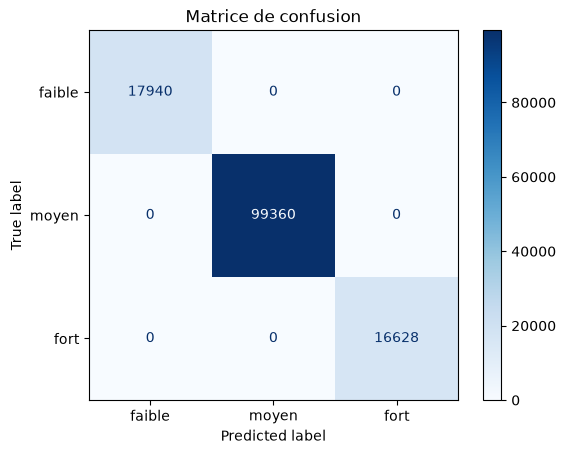

In [2]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["faible", "moyen", "fort"], cmap="Blues"
)
plt.title("Matrice de confusion")
plt.show()

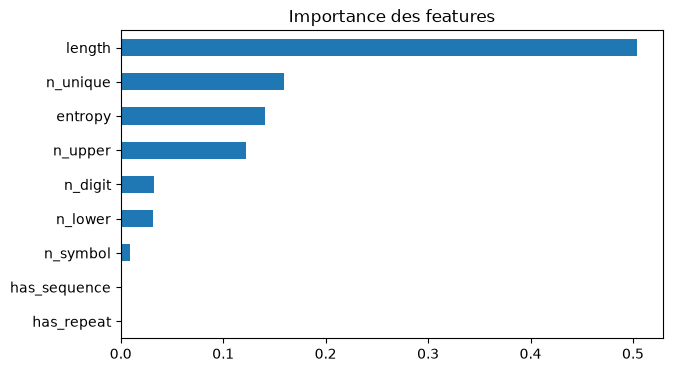

In [7]:
imp = pd.Series(model.feature_importances_, index=Xm_train.columns).sort_values()
imp.plot(kind="barh", figsize=(7, 4), title="Importance des features")
plt.show()

In [8]:
from zxcvbn import zxcvbn

df = pd.read_csv("../data/data.csv", on_bad_lines="skip").dropna().drop_duplicates().reset_index(drop=True)
df["password"] = df["password"].astype(str)

rng = np.random.RandomState(42)
sample = rng.choice(len(idx_test), 3000, replace=False)
pw_sample = df["password"].iloc[idx_test[sample]].tolist()

def zx_class(pw):
    s = zxcvbn(pw[:72])["score"]
    return 0 if s <= 1 else (1 if s <= 3 else 2)

zx_pred = np.array([zx_class(p) for p in pw_sample])
y_true = y_test[sample]
model_pred = pred[sample]

print("zxcvbn vs étiquettes du dataset :", round((zx_pred == y_true).mean(), 3))
print("Modèle vs étiquettes du dataset :", round((model_pred == y_true).mean(), 3))
print("Modèle vs zxcvbn               :", round((model_pred == zx_pred).mean(), 3))

pd.crosstab(y_true, zx_pred, rownames=["dataset"], colnames=["zxcvbn"])

zxcvbn vs étiquettes du dataset : 0.77
Modèle vs étiquettes du dataset : 1.0
Modèle vs zxcvbn               : 0.77


zxcvbn,0,1,2
dataset,,,
0,275,143,0
1,326,1657,209
2,0,12,378


In [9]:
tests = ["123456", "password", "Password1!", "k#9Tz$vQ2@mL", "azerty2024", "MonChat!Dort1Sur2Canape"]
noms = ["faible", "moyen", "fort"]

rows = []
for p in tests:
    f = pd.DataFrame([extract_features(p)])
    rows.append({
        "mot de passe": p,
        "modèle": noms[model.predict(f)[0]],
        "zxcvbn (0-4)": zxcvbn(p)["score"],
    })
pd.DataFrame(rows)

,mot de passe,modèle,zxcvbn (0-4)
0,123456,faible,0
1,password,moyen,0
2,Password1!,moyen,1
3,k#9Tz$vQ2@mL,moyen,4
4,azerty2024,moyen,2
5,MonChat!Dort1Sur2Canape,fort,4


In [10]:
joblib.dump(model, "../models/model_rf.pkl")

['../models/model_rf.pkl']